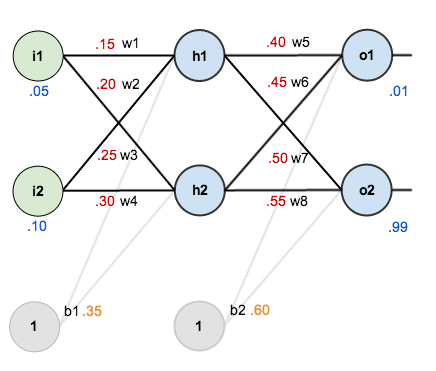

In [1]:
from IPython.display import Image
Image("image.png")

In [2]:
##############################################################################
# Implementation of a A Step by Step Backpropagation Example by Matt Mazur
# https://mattmazur.com/2015/03/17/a-step-by-step-backpropagation-example/
##############################################################################

# Original code: https://github.com/vendidad/DS-repo/blob/master/Backpropagation%20-%20Consolidated%20Script.ipynb


import numpy as np
np.set_printoptions(precision=4)

def initialize():
    X = np.array([[0.05, 0.10]])      # Inputs
    W1 = np.array([[0.15,0.20], [0.25,0.30]])      # Weights to calculate outputs for hidden layer 1
    b1 = 0.35      # Bias for hidden layer 1
    W2 = np.array([[0.40,0.45], [0.50,0.55]])     # Weights to calculate outputs for output layer
    b2 = 0.60      # Bias for output layer
    Y = np.array([[0.01, 0.99]])      # Desired output
    learning_rate = 0.5
    no_of_iter = int(100)
    return (X, W1, b1, W2, b2, Y, learning_rate, no_of_iter)

def forward_pass (X, W1, b1, W2, b2, Y):
    ### Forward pass: Calculate hidden layer 1 (there is only 1 hidden layer in this example)
    Z1 = np.dot(X,W1.T) + b1      # WtX + b
    A1 = 1/(1 + np.exp(-Z1))       # Sigmoid(z) = 1 / (1 + e^(-z))
    ### Forward pass: Calculate output layer
    Z2 = np.dot(A1,W2.T) + b2      # WtX + b
    A2 = 1/(1 + np.exp(-Z2))       # Sigmoid(z) = 1 / (1 + e^(-z))
    ### Calculate error/cost function
    E = np.sum(1/2*np.square(Y - A2))      # squared error function
    return (A1, A2, E)

def back_propagation(X, W1, W2, Y, A1, A2, learning_rate):
    ### Back propogation
    ### Adjust W2
    dEdA2 = A2 - Y
    dA2dZ2 = np.multiply (A2,1-A2)
    dZ2dW2 = A1
    dEdW2 = dEdA2 * dA2dZ2 * dZ2dW2
    W2_adj = W2 - learning_rate * dEdW2.T
    W2 = W2_adj
    ### Adjust W1
    dZ2dA1 = W2.T
    dA1dZ1 = np.multiply(A1,1-A1)
    dZ1dW1 = X
    dEdW1 = dEdA2 * dA2dZ2 * dZ2dA1 * dA1dZ1 * dZ1dW1
    W1_adj = W1 - learning_rate * dEdW1.T
    W1 = W1_adj
    return (W1, W2)

def main():
    (X, W1, b1, W2, b2, Y, learning_rate, no_of_iter) = initialize()
    for iter in range (0,no_of_iter):
        (A1, A2, E) = forward_pass(X, W1, b1, W2, b2, Y)
        (W1, W2) = back_propagation(X, W1, W2, Y, A1, A2, learning_rate)
    print ('W1 = {} \n\n W2 = {} \n\n Output = {} \n Desired output = {} \n Error = {}'.format(W1, W2, A2, Y, E))

main()

W1 = [[0.1826 0.2304]
 [0.2705 0.3217]] 

 W2 = [[-1.819  -1.769 ]
 [ 1.1239  1.1739]] 

 Output = [[0.178  0.8771]] 
 Desired output = [[0.01 0.99]] 
 Error = 0.020492276763740064


## Original run (100 iterations)
The output above is far from the target `[0.01, 0.99]`.

## Increasing the number of iterations (epochs)
`main()` is changed to accept the number of iterations, and the error is recorded at every iteration so it can be plotted.

In [3]:
def train(no_of_iter):
    (X, W1, b1, W2, b2, Y, learning_rate, _) = initialize()
    errors = []
    for i in range(no_of_iter):
        (A1, A2, E) = forward_pass(X, W1, b1, W2, b2, Y)
        errors.append(E)
        (W1, W2) = back_propagation(X, W1, W2, Y, A1, A2, learning_rate)
    (A1, A2, E) = forward_pass(X, W1, b1, W2, b2, Y)   # final prediction with trained weights
    return W1, W2, A2, E, errors

iteration_list = [100, 500, 1000, 5000, 10000, 20000]
results = {}
print(f"{'Iterations':>10} | {'Output o1':>10} | {'Output o2':>10} | {'Error':>12}")
print('-' * 52)
for n in iteration_list:
    W1, W2, A2, E, errors = train(n)
    results[n] = errors
    print(f"{n:>10} | {A2[0,0]:>10.4f} | {A2[0,1]:>10.4f} | {E:>12.8f}")
print('Desired output: o1 = 0.01, o2 = 0.99')

Iterations |  Output o1 |  Output o2 |        Error
----------------------------------------------------
       100 |     0.1768 |     0.8776 |   0.02022598
       500 |     0.0645 |     0.9401 |   0.00273124
      1000 |     0.0446 |     0.9569 |   0.00114635
      5000 |     0.0212 |     0.9790 |   0.00012288
     10000 |     0.0162 |     0.9839 |   0.00003792
     20000 |     0.0130 |     0.9870 |   0.00000878
Desired output: o1 = 0.01, o2 = 0.99


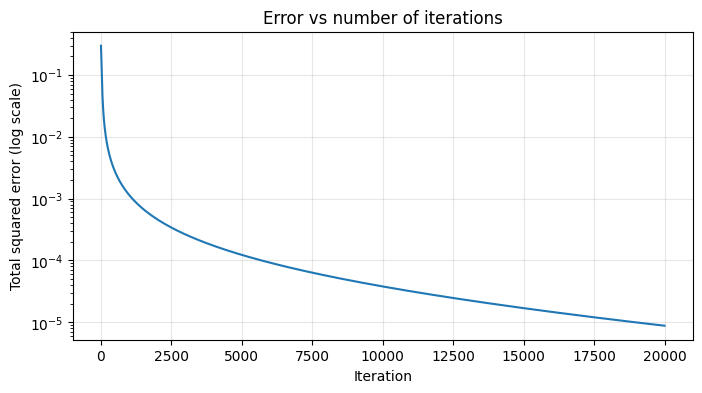

In [4]:
import matplotlib.pyplot as plt
errors = results[max(iteration_list)]
plt.figure(figsize=(8,4))
plt.plot(errors)
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Total squared error (log scale)')
plt.title('Error vs number of iterations')
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
# Final weights after the largest run
W1, W2, A2, E, _ = train(20000)
print('W1 =\n', W1, '\n\nW2 =\n', W2, '\n\nOutput =', A2, '\nDesired =', [[0.01, 0.99]], '\nError =', E)

W1 =
 [[0.3208 0.3662]
 [0.4345 0.4897]] 

W2 =
 [[-4.1249 -4.0749]
 [ 3.0783  3.1283]] 

Output = [[0.013 0.987]] 
Desired = [[0.01, 0.99]] 
Error = 8.779379911729512e-06
